In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('placement.csv')

In [4]:
df.shape

(1000, 3)

In [5]:
df.sample(5)

,cgpa,placement_exam_marks,placed
25,6.28,58.0,1
885,7.13,16.0,1
868,7.33,36.0,0
289,6.73,9.0,1
549,7.37,79.0,1


In [11]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

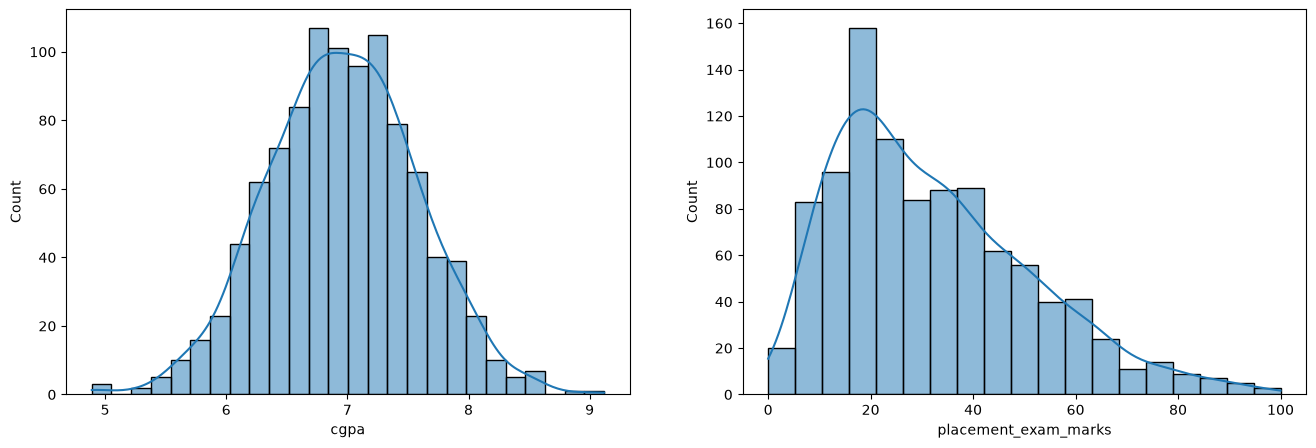

In [8]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['cgpa'], kde=True)

plt.subplot(1, 2, 2)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.show()

In [9]:
df['placement_exam_marks'].skew()

np.float64(0.8356419499466834)

In [10]:
df['cgpa'].skew()

np.float64(-0.014529938929314918)

<Axes: ylabel='placement_exam_marks'>

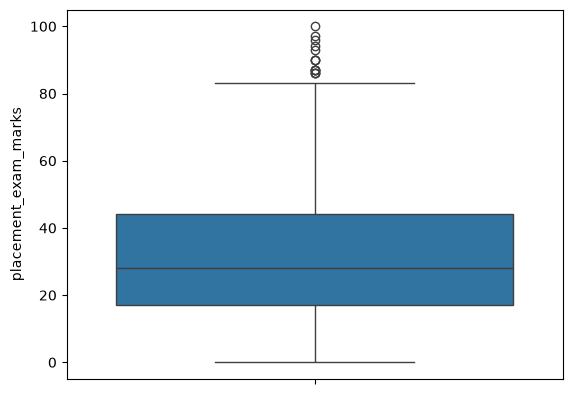

In [13]:
sns.boxplot(df['placement_exam_marks']) # from o/p its is right skewwed

In [14]:
# finding the iqr
percentile25 = df['placement_exam_marks'].quantile(0.25)
percentile75 = df['placement_exam_marks'].quantile(0.75)

In [16]:
percentile25

np.float64(17.0)

In [17]:
percentile75

np.float64(44.0)

In [18]:
iqr = percentile75 - percentile25

In [19]:
iqr

np.float64(27.0)

In [20]:
upper_limit = percentile75 + 1.5*iqr
lower_limit = percentile25 - 1.5*iqr

In [21]:
print("Upper limit", upper_limit)
print('Lower limit', lower_limit)

Upper limit 84.5
Lower limit -23.5


# Finding Outliers

In [22]:
df[df['placement_exam_marks']>upper_limit]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [24]:
df[df['placement_exam_marks']<lower_limit]

,cgpa,placement_exam_marks,placed


# Trimming

In [28]:
new_df = df[df['placement_exam_marks']<upper_limit] # we do for only upper limit becasue lower limit has no value rn

In [33]:
new_df.shape # 15 outliers are remove

(985, 3)

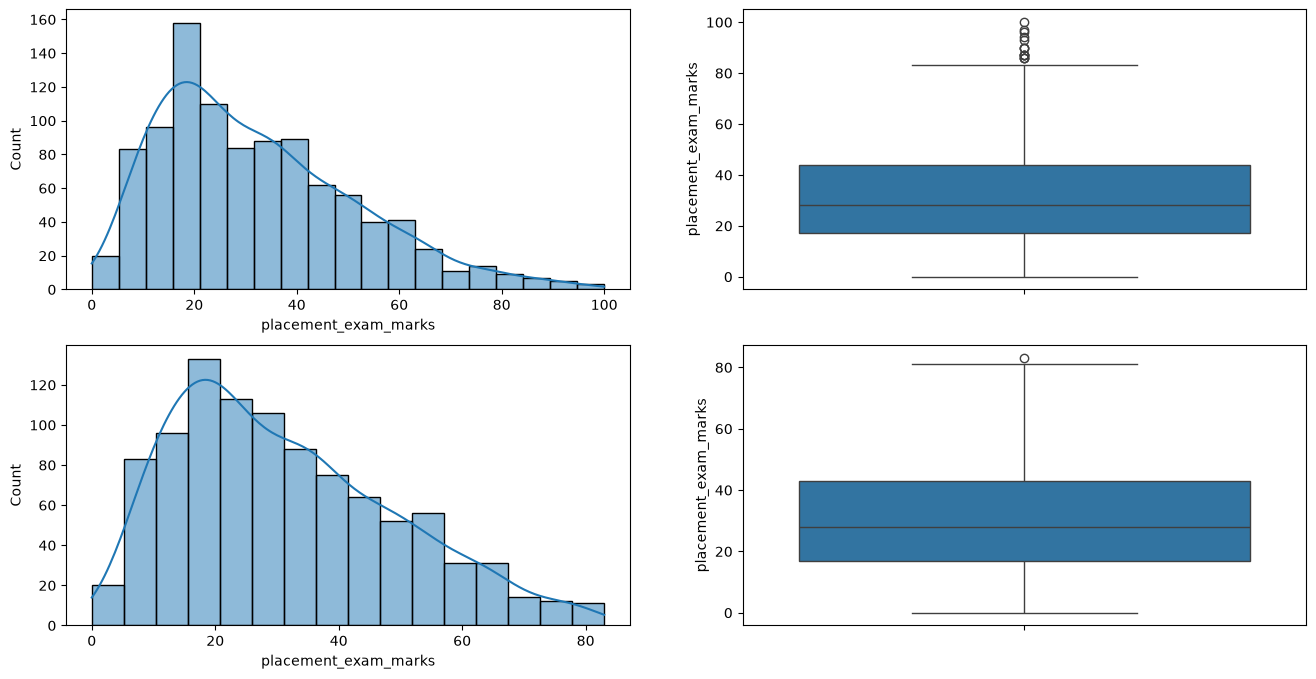

In [36]:
# comparingggg

plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.histplot(df['placement_exam_marks'], kde = True)

plt.subplot(2,2,2)
sns.boxplot(df['placement_exam_marks'])

plt.subplot(2,2,3)
sns.histplot(new_df['placement_exam_marks'], kde=True)

plt.subplot(2,2,4)
sns.boxplot(new_df['placement_exam_marks'])

plt.show()
# see figure and the outliers are removed

# Capping

In [40]:
new_df_cap = df.copy()

''' 
np.where(
    condition_1,
    value_if_1_true,
    np.where(
        condition_2,
        value_if_2_true,
        value_if_both_false
    )
)'''
 # np.where(condition,true, false)

new_df_cap['placement_exam_marks'] = np.where(
    new_df_cap['placement_exam_marks']>upper_limit,
    upper_limit,
    np.where(
        new_df_cap['placement_exam_marks']<lower_limit,
        lower_limit,
        new_df_cap['placement_exam_marks']
    )
)

In [41]:
new_df_cap.shape

(1000, 3)

<Axes: ylabel='placement_exam_marks'>

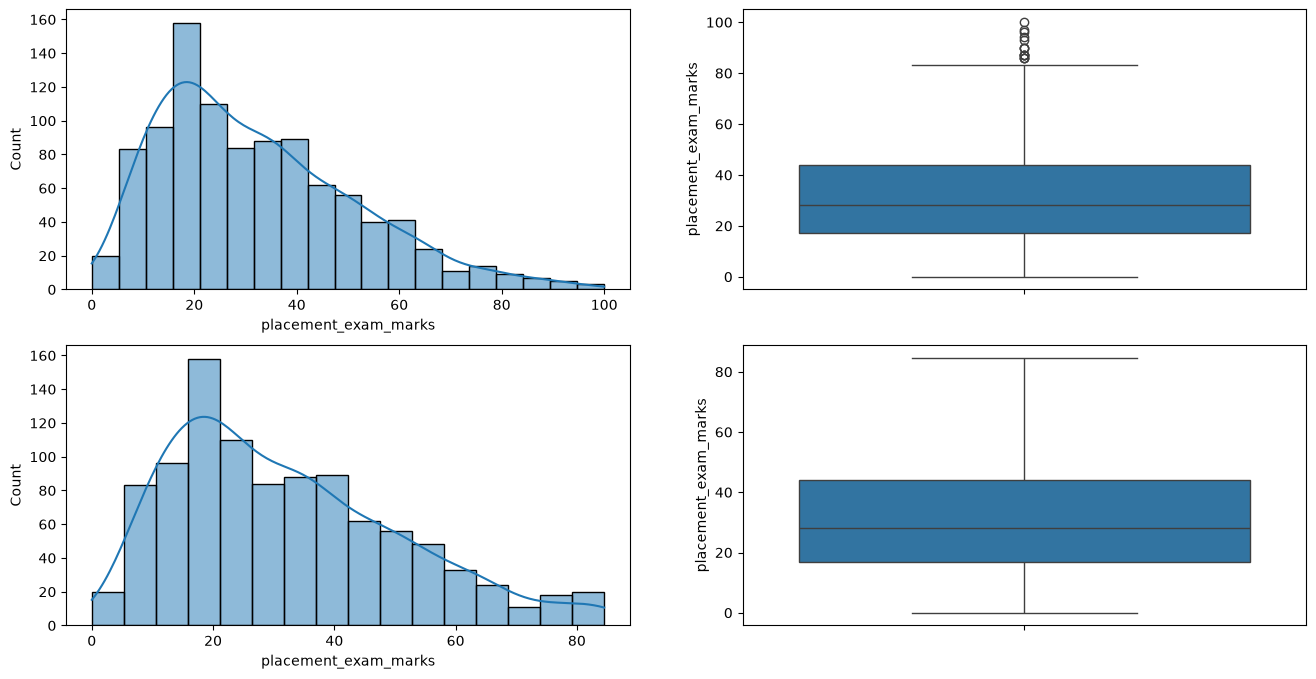

In [44]:
# comparing

plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.subplot(2,2,2)
sns.boxplot(df['placement_exam_marks'])

plt.subplot(2,2,3)
sns.histplot(new_df_cap['placement_exam_marks'], kde=True)

plt.subplot(2,2,4)
sns.boxplot(new_df_cap['placement_exam_marks'])